# Manufacturing Process Analytics & Optimization
## Phase 1: synthetic demonstration data
All observations are synthetic. This notebook reuses the tested project functions. No real employer data, causal claims, or optimization are included.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.run_pipeline import main
from src.data_quality import validate_data
main()

{
  "rows": 3000,
  "means": {
    "yield_percent": 91.59543333333333,
    "defect_rate_percent": 7.0815,
    "energy_kWh": 36.41628333333333
  },
  "regions": {
    "candidate_screen": {
      "batch_count": 330,
      "yield_percent": 95.55939393939393,
      "defect_rate_percent": 3.034545454545454,
      "energy_kWh": 37.58339696969696
    },
    "outside_candidate_screen": {
      "batch_count": 2670,
      "yield_percent": 91.10550561797753,
      "defect_rate_percent": 7.581685393258426,
      "energy_kWh": 36.27203333333333
    },
    "short_cycle": {
      "batch_count": 194,
      "yield_percent": 78.99123711340206,
      "defect_rate_percent": 19.85979381443299,
      "energy_kWh": 31.393494845360824
    },
    "outside_short_cycle": {
      "batch_count": 2806,
      "yield_percent": 92.46685673556664,
      "defect_rate_percent": 6.198039914468994,
      "energy_kWh": 36.76354668567356
    },
    "temperature_tails": {
      "batch_count": 301,
      "yield_percent": 81.70

## 1. Validate persisted batches
Each batch has 1,000 input units. First-pass yield, tracked defects, and other losses are disjoint and sum to 100%.

In [2]:
data = pd.read_csv(ROOT / "data/raw/synthetic_batches.csv", parse_dates=["timestamp"])
display(pd.Series(validate_data(data), name="passed"))
display(data.head())
display(data.describe())

expected_row_count             True
no_missing_values              True
no_duplicate_rows              True
unique_batch_ids               True
batch_id_format                True
timestamp_dtype                True
unique_timestamps              True
ordered_timestamps             True
valid_materials                True
valid_machines                 True
synthetic_label                True
temperature_C_numeric          True
temperature_C_range            True
pressure_MPa_numeric           True
pressure_MPa_range             True
cycle_time_min_numeric         True
cycle_time_min_range           True
yield_percent_numeric          True
yield_percent_range            True
defect_rate_percent_numeric    True
defect_rate_percent_range      True
other_loss_percent_numeric     True
other_loss_percent_range       True
energy_kWh_numeric             True
energy_kWh_range               True
unit_balance                   True
Name: passed, dtype: bool

,batch_id,timestamp,material_type,machine_id,temperature_C,pressure_MPa,cycle_time_min,yield_percent,defect_rate_percent,other_loss_percent,energy_kWh,data_origin
0,B00001,2025-01-01 00:00:00,B,M2,183.24,5.429,12.92,97.9,1.1,1.0,36.788,synthetic_demonstration
1,B00002,2025-01-01 00:30:00,A,M3,174.43,5.681,12.76,94.9,3.4,1.7,36.398,synthetic_demonstration
2,B00003,2025-01-01 01:00:00,C,M2,165.73,4.427,12.14,96.8,1.4,1.8,30.638,synthetic_demonstration
3,B00004,2025-01-01 01:30:00,B,M2,167.25,5.013,13.59,94.7,3.5,1.8,36.144,synthetic_demonstration
4,B00005,2025-01-01 02:00:00,A,M2,179.42,5.138,8.86,95.9,3.0,1.1,31.842,synthetic_demonstration


,timestamp,temperature_C,pressure_MPa,cycle_time_min,yield_percent,defect_rate_percent,other_loss_percent,energy_kWh
count,3000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,2025-02-01 05:45:00.000000512,180.590297,4.975755,11.958940,91.595433,7.081500,1.323067,36.416283
min,2025-01-01 00:00:00,140.000000,2.500000,6.000000,8.100000,0.500000,0.000000,22.537000
25%,2025-01-16 14:52:30,172.517500,4.477750,10.630000,91.000000,3.000000,0.900000,33.092500
50%,2025-02-01 05:45:00,180.340000,4.964000,11.930000,94.000000,4.500000,1.300000,36.276500
75%,2025-02-16 20:37:30,188.685000,5.481250,13.290000,95.700000,7.600000,1.700000,39.409000
max,2025-03-04 11:30:00,220.000000,7.500000,19.000000,98.800000,91.700000,3.800000,57.341000
std,NaN,12.157096,0.759246,1.990742,8.528368,8.624324,0.596445,4.825457


## 2. Compare distributions and groups
Inspect spread as well as means. Machine and material averages are unadjusted descriptive comparisons.

yield_percent                      defect_rate_percent            \
                   count       mean       std               count      mean   
machine_id                                                                    
M1                  1050  92.410095  8.121002                1050  6.246667   
M2                   993  91.759517  7.690496                 993  6.907049   
M3                   957  90.531348  9.619672                 957  8.178474   

                     energy_kWh                       
                 std      count       mean       std  
machine_id                                            
M1          8.223082       1050  35.293828  4.730599  
M2          7.760333        993  36.259530  4.588075  
M3          9.728291        957  37.810468  4.826186

yield_percent                      defect_rate_percent  \
                      count       mean       std               count   
material_type                                                          
A                      1355  91.797417  7.795706                1355   
B                      1036  91.230695  9.714149                1036   
C                       609  91.766502  7.901673                 609   

                                  energy_kWh                       
                   mean       std      count       mean       std  
material_type                                                      
A              6.869373  7.879261       1355  36.299845  4.888578  
B              7.446911  9.832794       1036  36.900905  4.685643  
C              6.931856  7.980418        609  35.850939  4.848641

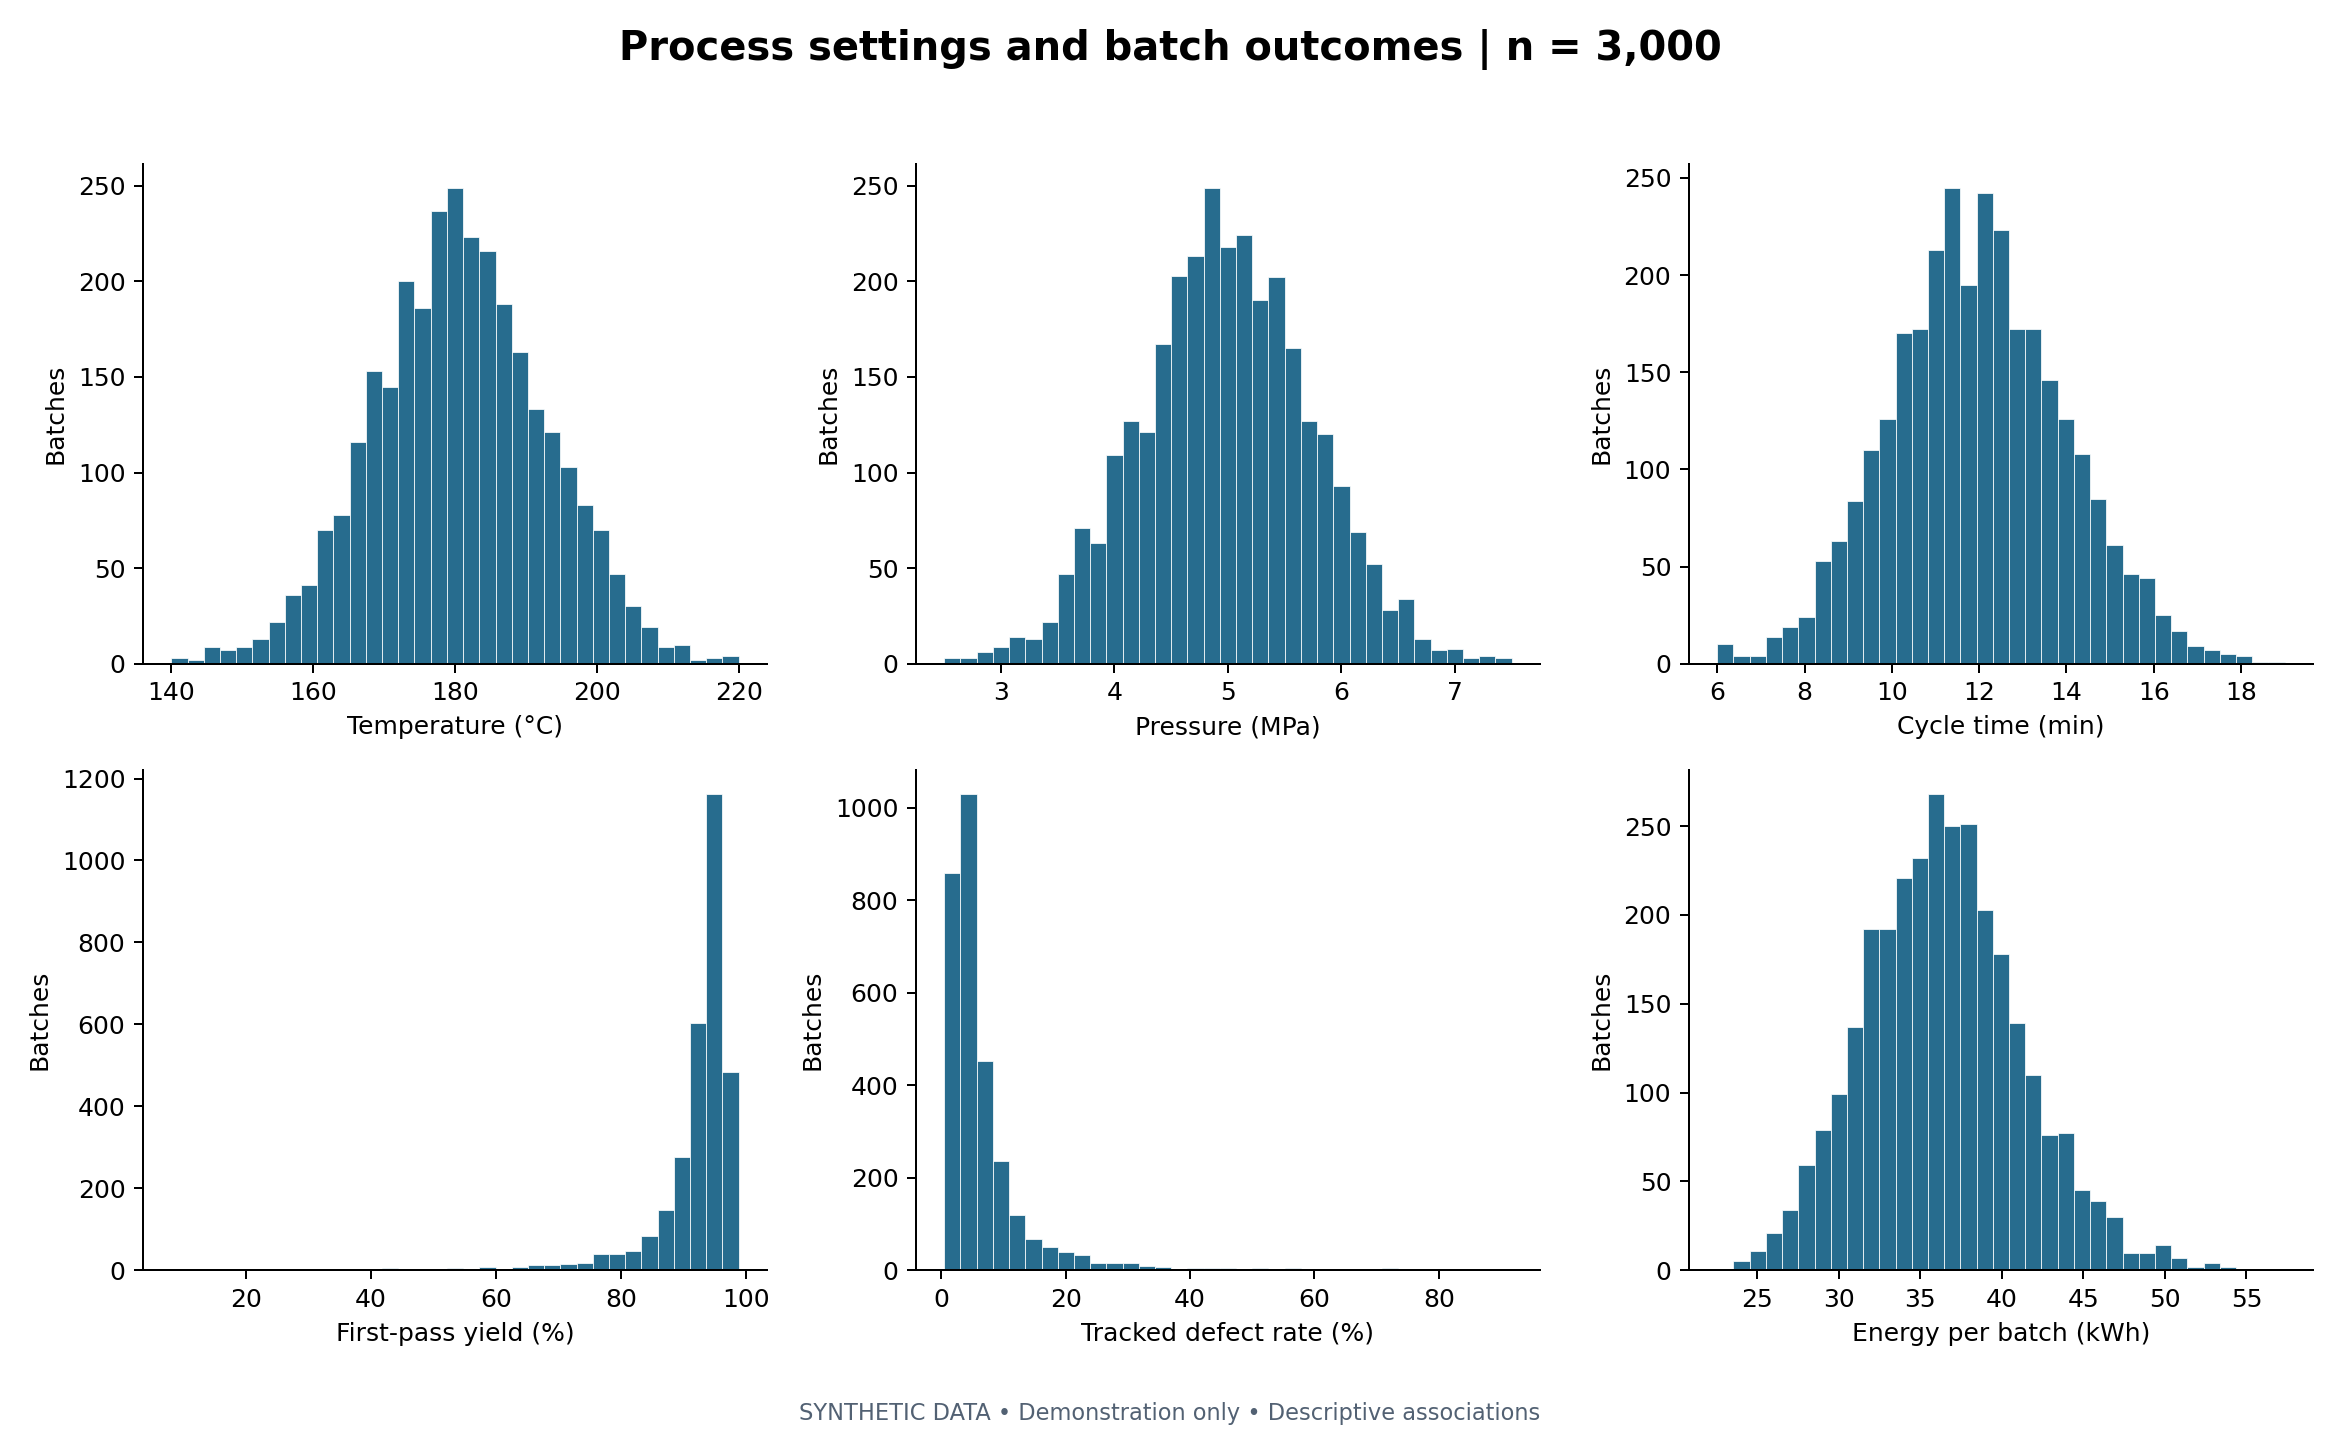

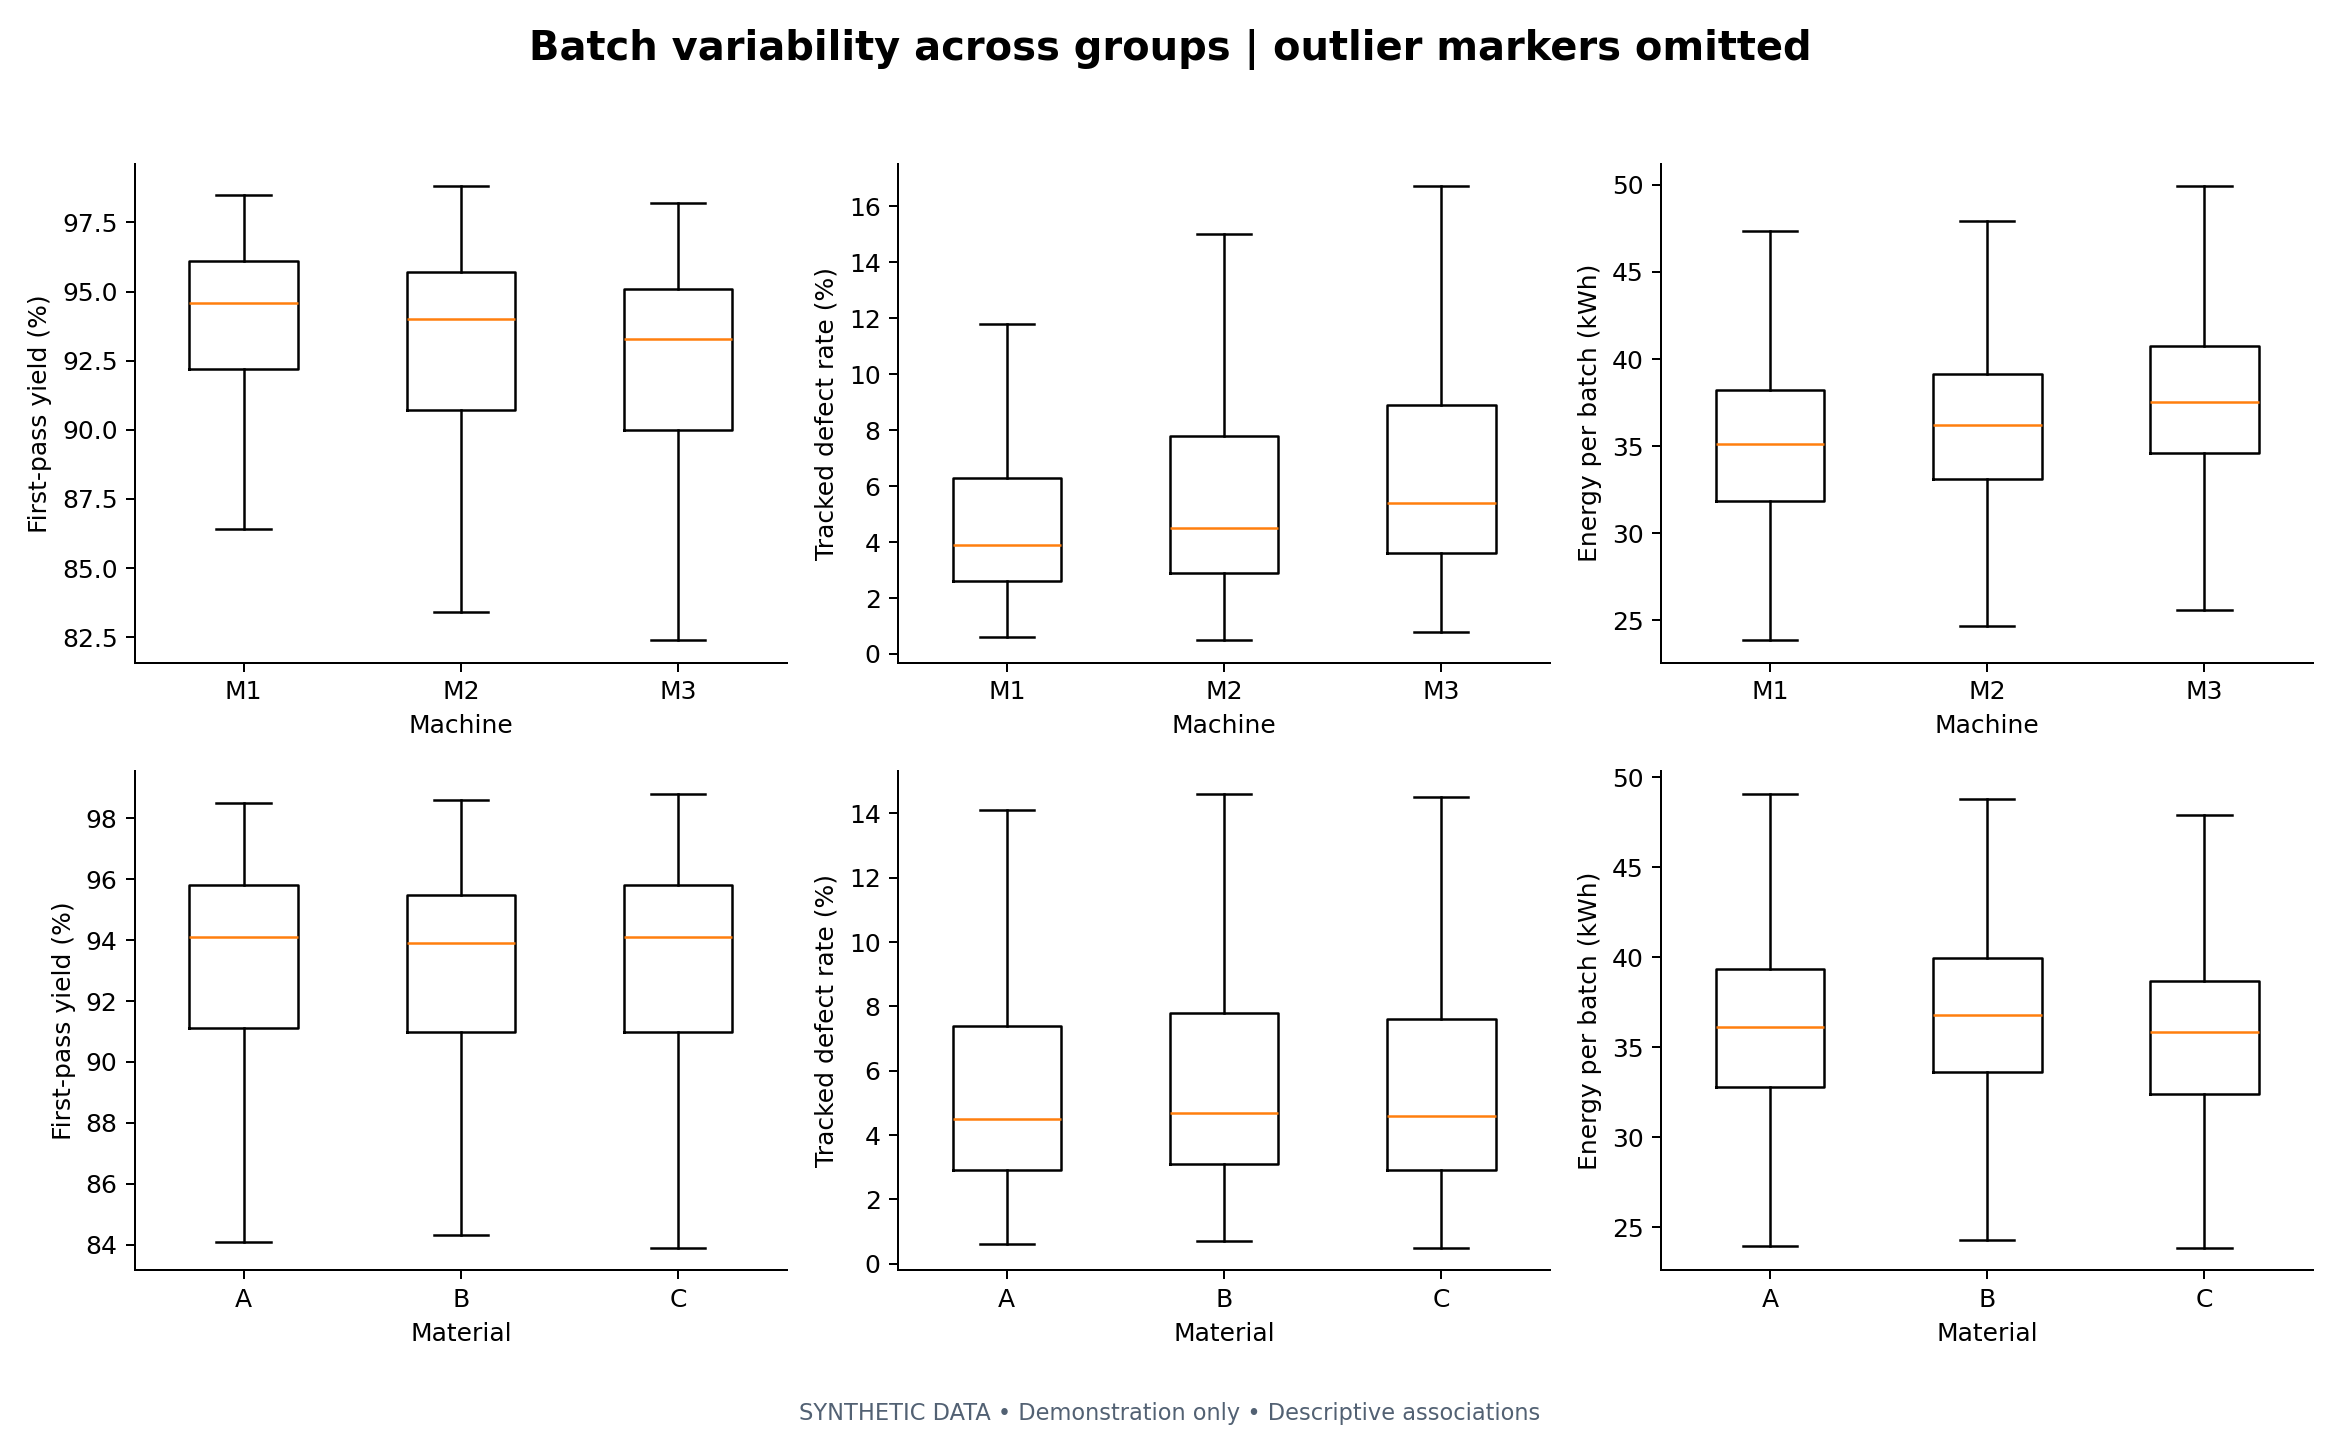

In [3]:
from src.analysis import OUTCOMES
for group in ["machine_id", "material_type"]:
    display(data.groupby(group)[OUTCOMES].agg(["count", "mean", "std"]))
for name in ["distributions", "group_comparisons"]:
    display(Image(filename=str(ROOT / "figures" / f"{name}.png")))

## 3. Explore process relationships
Squared response terms create nonlinear associations. A near-zero Pearson correlation does not imply that a setting has no relationship with defects. Yield and defects are linked by the unit balance.

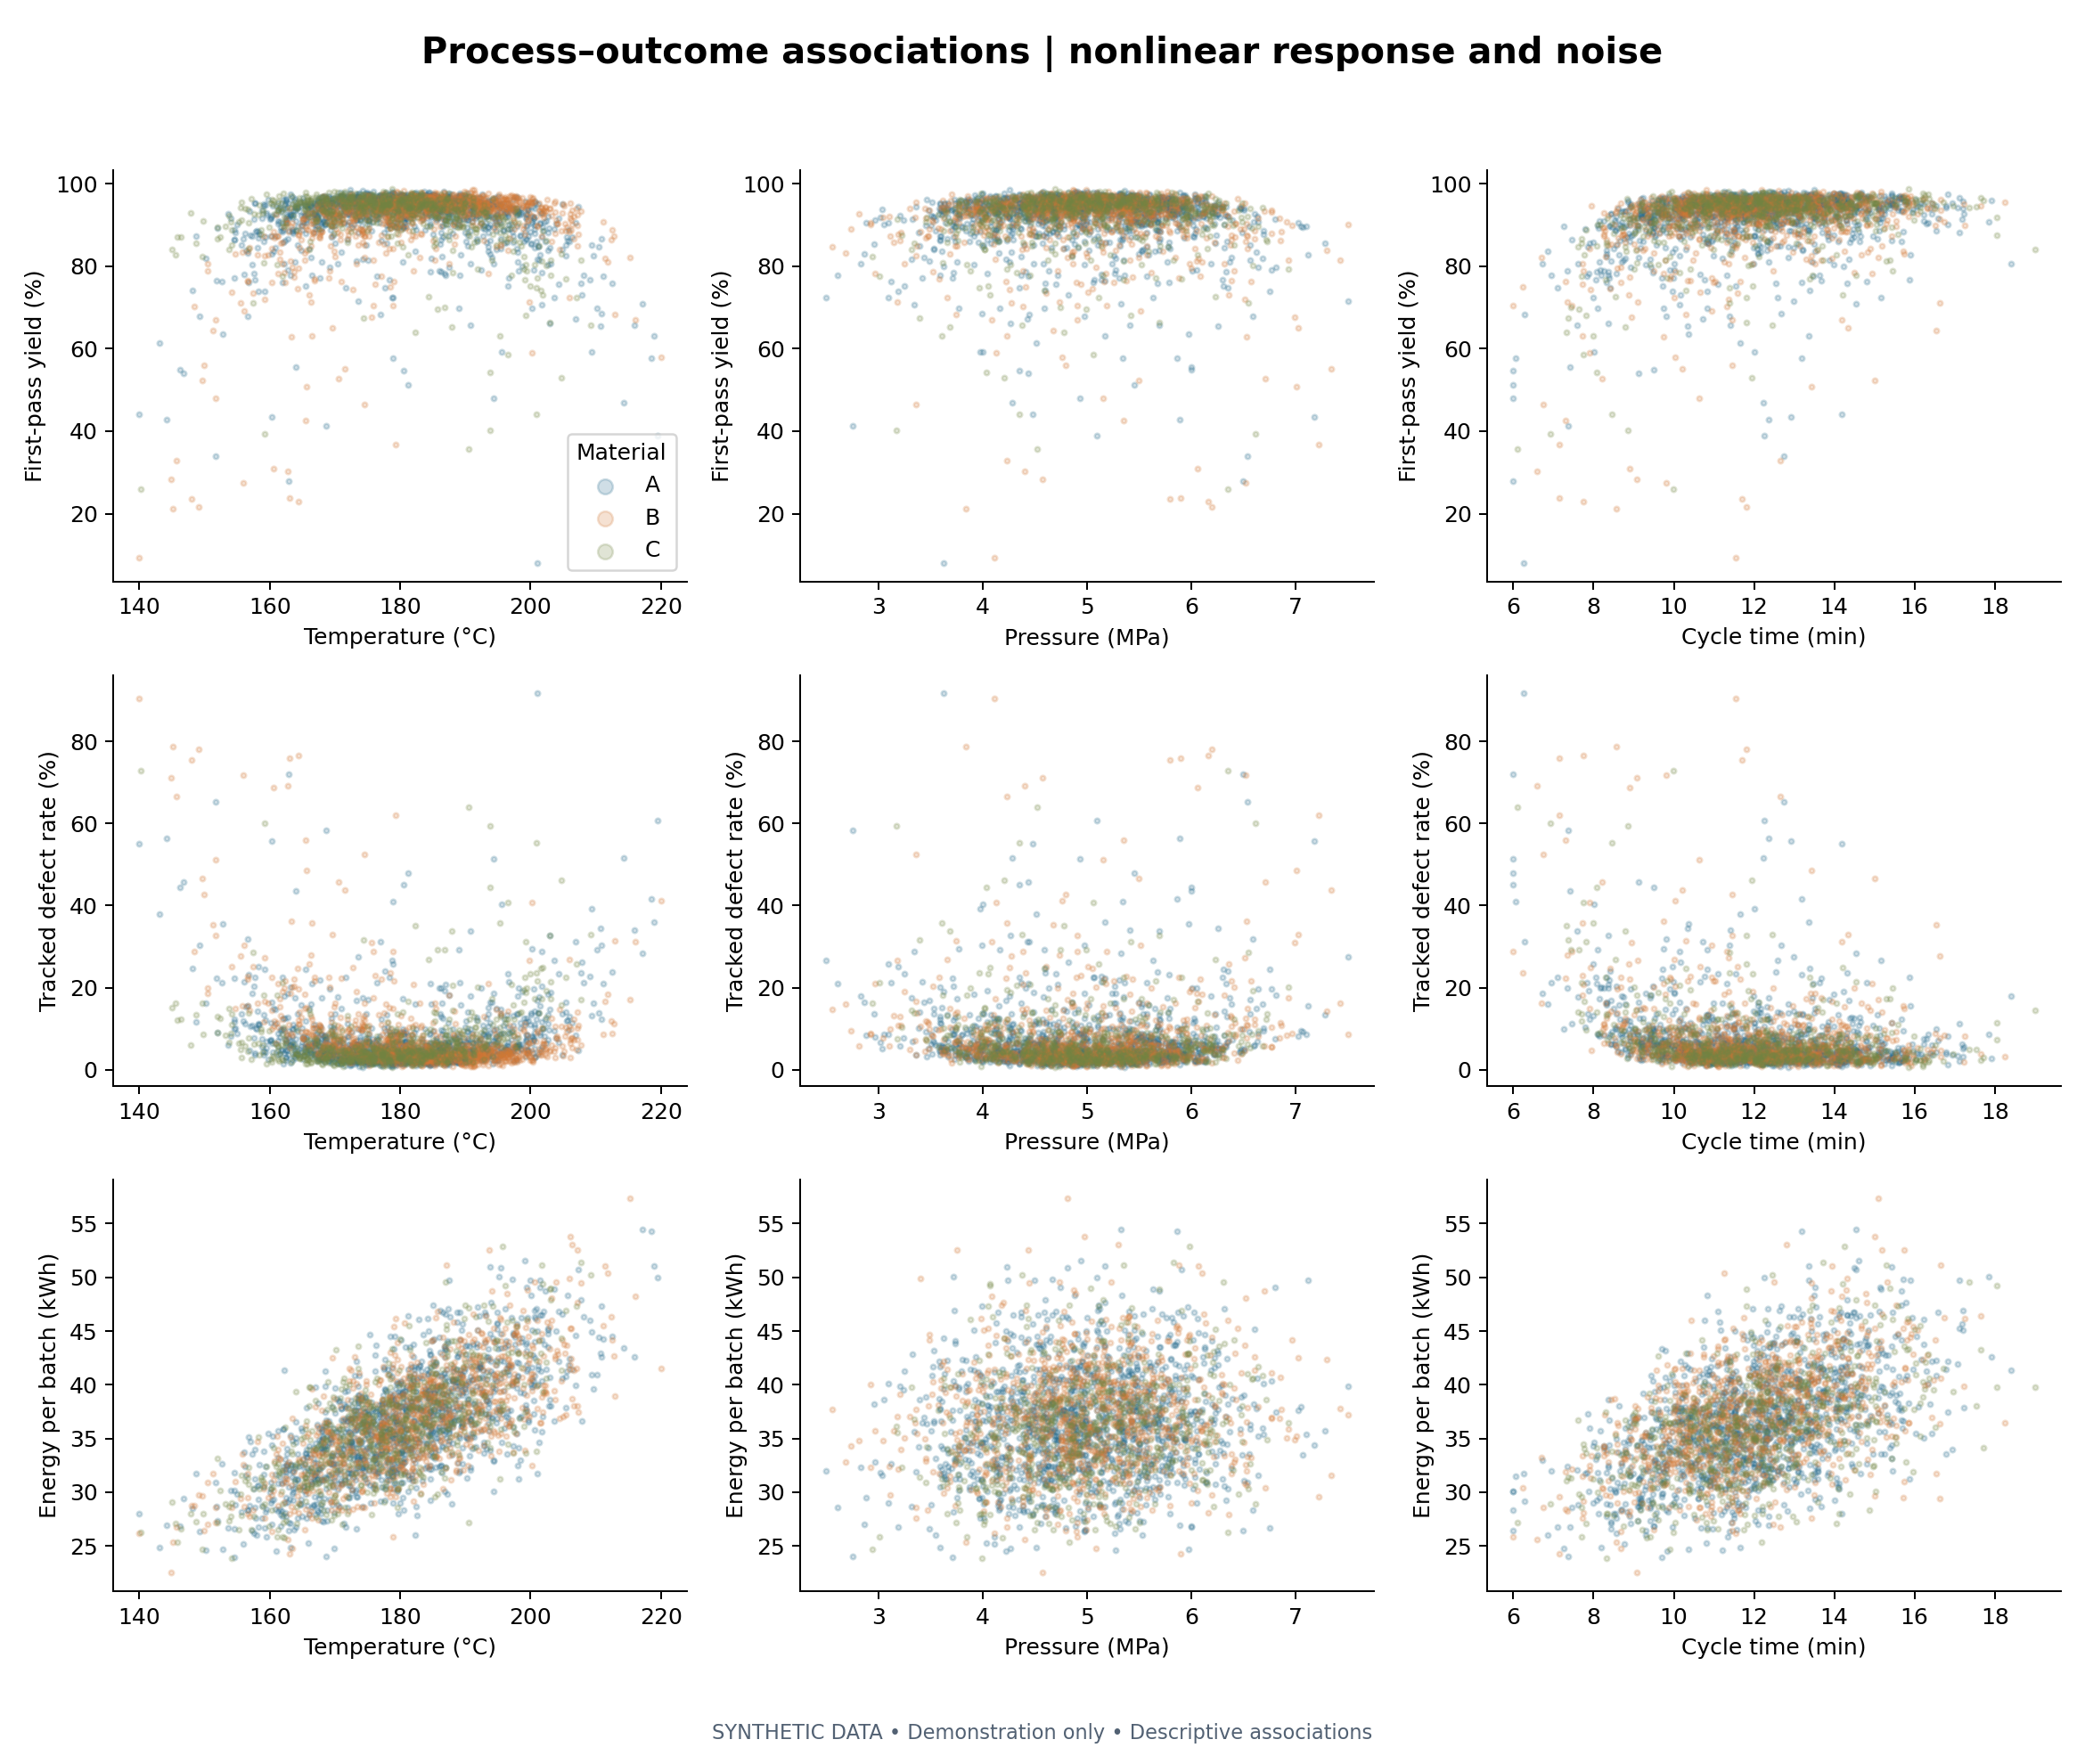

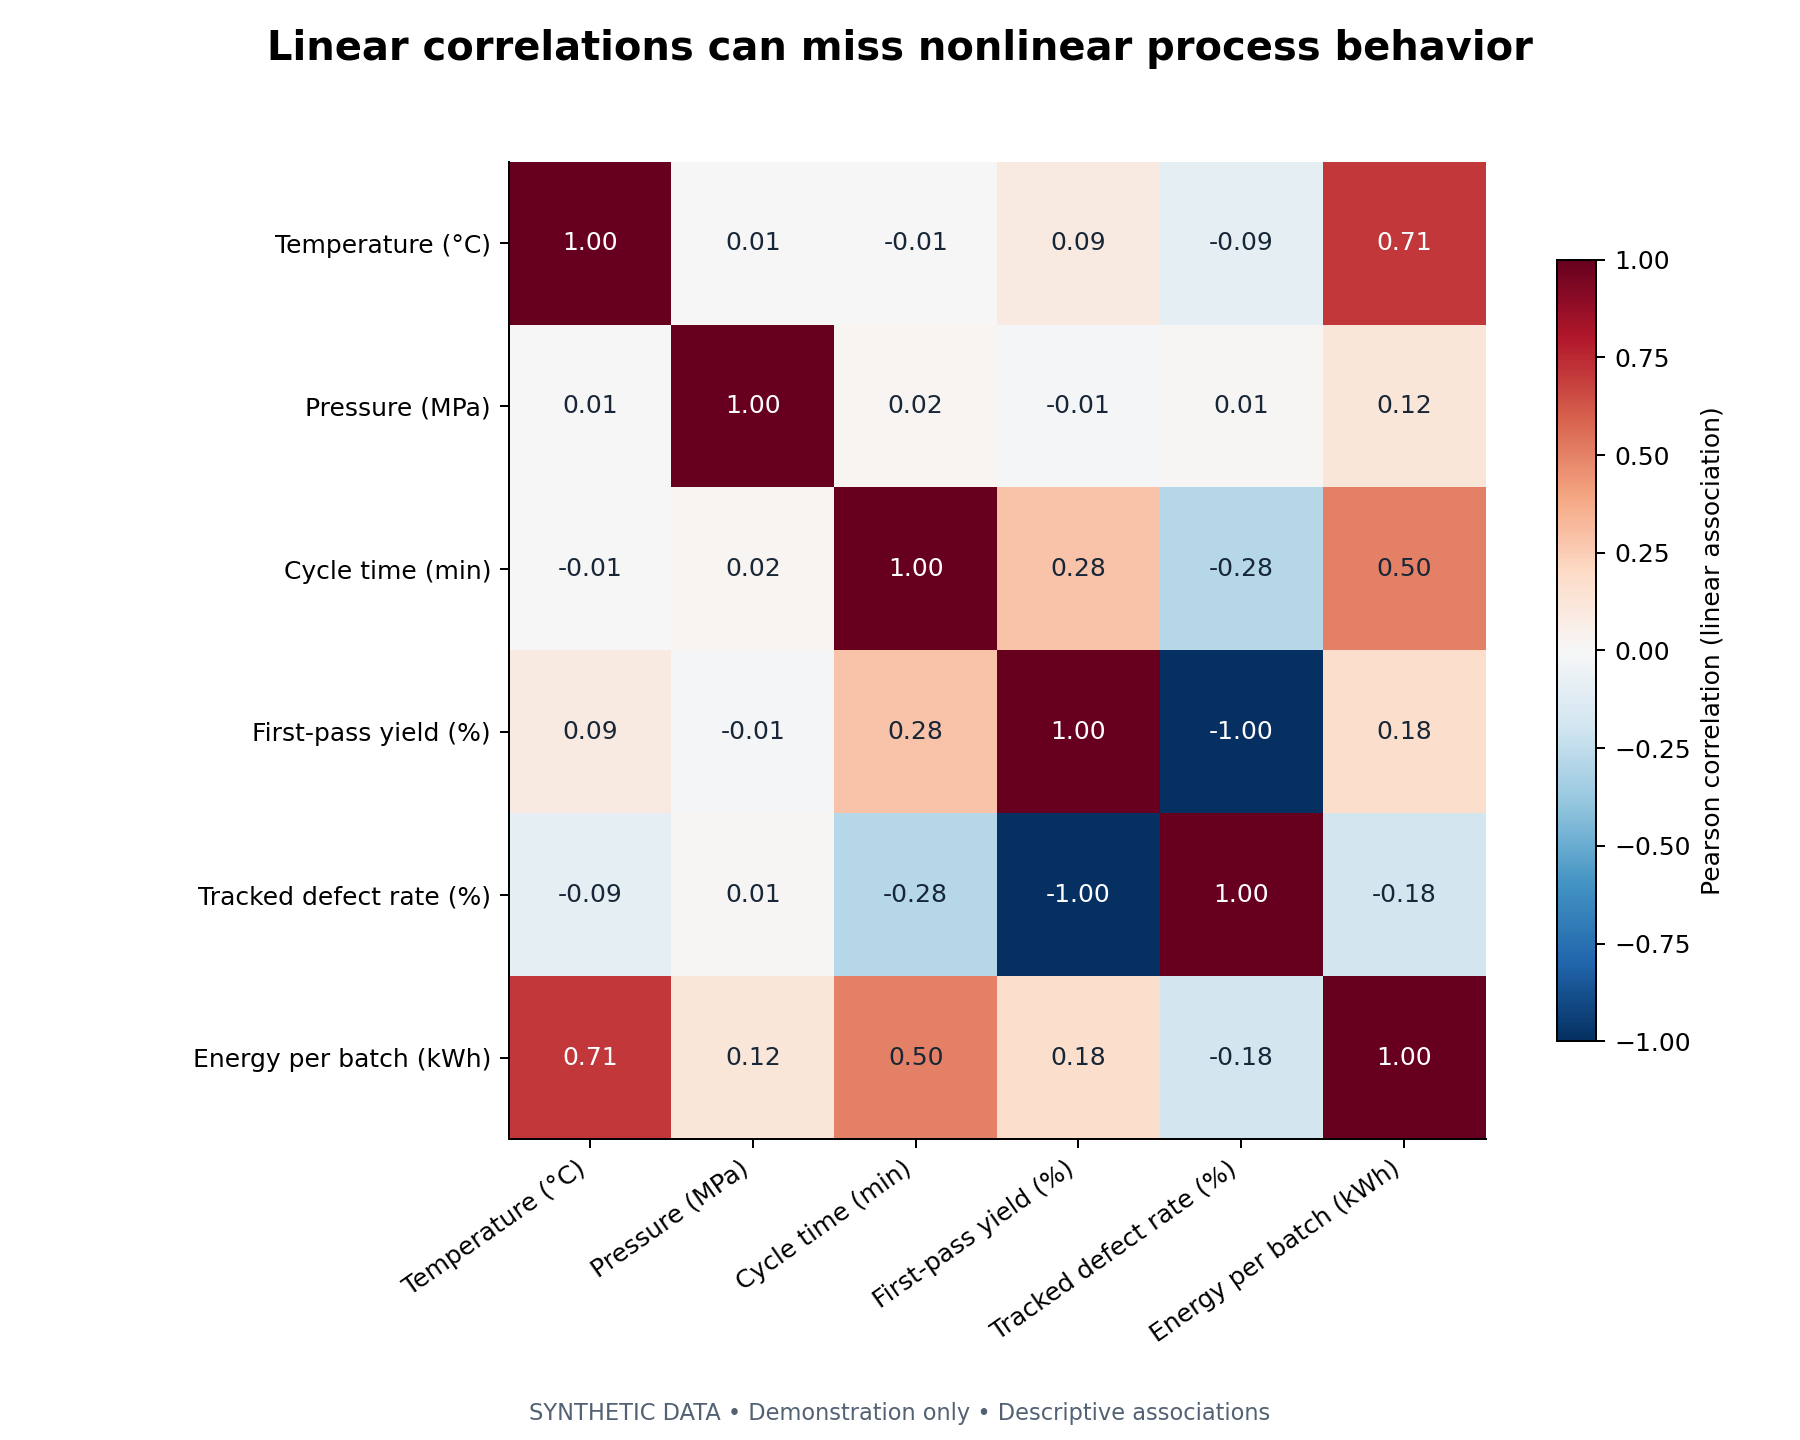

,temperature_C,pressure_MPa,cycle_time_min,yield_percent,defect_rate_percent,energy_kWh
temperature_C,1.000000,0.006459,-0.005335,0.088142,-0.088588,0.706577
pressure_MPa,0.006459,1.000000,0.020462,-0.010817,0.010738,0.120448
cycle_time_min,-0.005335,0.020462,1.000000,0.281988,-0.283186,0.504521
yield_percent,0.088142,-0.010817,0.281988,1.000000,-0.997644,0.178848
defect_rate_percent,-0.088588,0.010738,-0.283186,-0.997644,1.000000,-0.180027
energy_kWh,0.706577,0.120448,0.504521,0.178848,-0.180027,1.000000


In [4]:
for name in ["process_relationships", "correlations"]:
    display(Image(filename=str(ROOT / "figures" / f"{name}.png")))
display(pd.read_csv(ROOT / "data/processed/correlations.csv", index_col=0))

## 4. Candidate regions and interpretation
Compare predefined screens with their complements. The candidate screen is an illustrative pooled region, not a recommended production window. Check sample sizes and the energy tradeoff before discussing it.

In [5]:
display(pd.read_csv(ROOT / "data/processed/region_comparisons.csv"))

,region,batch_count,yield_percent,defect_rate_percent,energy_kWh
0,candidate_screen,330,95.559394,3.034545,37.583397
1,outside_candidate_screen,2670,91.105506,7.581685,36.272033
2,short_cycle,194,78.991237,19.859794,31.393495
3,outside_short_cycle,2806,92.466857,6.198040,36.763547
4,temperature_tails,301,81.706312,17.149502,37.365086
5,outside_temperature_tails,2699,92.698296,5.958688,36.310470


## Review questions
- How do the material reference temperatures affect the scatterplots?
- Why is the yield–defect correlation partly definitional?
- What could change if batch size, material mix, or process variability changed?
- What real measurements and controlled experiments would be needed to validate a candidate region?

Phase 2 modeling, DOE, SPC, and optimization are deferred until explicit approval.